<a href="https://colab.research.google.com/github/CoralsINPA/RedSeaCoralIdentifier/blob/claude%2Ffervent-cerf-h6mv5z/CoralMasking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from google.colab import drive

# 1. FORCE THE MOUNT WAKE-UP
print("🔄 Waking up Google Drive connection...")
drive.mount('/content/drive', force_remount=True)

# 2. RUN PATH VERIFICATION
RUN_NAME = "iou60_sta55_pts32"
base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path = os.path.join(base_path, 'data_all')
run_dir = os.path.join(base_path, 'results_all', RUN_NAME)
json_dir = os.path.join(run_dir, 'json')

if os.path.exists(json_dir):
    print(f"✅ Drive link active! Found the json folder securely.")
else:
    print(f"❌ Path link failed. Still sleeping.")

🔄 Waking up Google Drive connection...
Mounted at /content/drive
✅ Drive link active! Found the json folder securely.


One time setup

In [ ]:
# import os
# import sys
# import shutil
# from google.colab import drive

# # 1. Mount Drive
# drive.mount('/content/drive')

# # 2. Setup Paths
# # You can change 'base_path' if you want to store this somewhere else
# base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
# repo_path = os.path.join(base_path, 'CoralSCOP')
# checkpoints_path = os.path.join(repo_path, 'checkpoints')
# lib_path = os.path.join(base_path, 'external_libs')

# # Create directories
# os.makedirs(lib_path, exist_ok=True)
# os.makedirs(checkpoints_path, exist_ok=True)

# # 3. Clone Repo
# if not os.path.exists(repo_path):
#     print("⬇️ Cloning CoralSCOP repository...")
#     !git clone https://github.com/zhengziqiang/CoralSCOP.git "{repo_path}"
# else:
#     print("✅ Repo already exists. Pulling latest updates...")
#     %cd "{repo_path}"
#     !git pull

# # 4. Install Dependencies (SAM & Helpers)
# print("⏳ Installing libraries... (Segment Anything, OpenCV, etc.)")
# # We install these permanently to your Colab runtime (they are fast to reinstall daily)
# !pip install git+https://github.com/facebookresearch/segment-anything.git
# !pip install opencv-python matplotlib pycocotools pandas

# # 5. Download Model Weights (Safe Version)
# # We check if the file exists AND if it's large enough (>100MB) to avoid empty files.
# weights_url = "https://huggingface.co/reefsupport/CoralSCOP/resolve/main/models/vit_b_coralscop.pth"
# weights_file = os.path.join(checkpoints_path, 'vit_b_coralscop.pth')

# if os.path.exists(weights_file):
#     # Check if file is corrupted (too small)
#     if os.path.getsize(weights_file) < 100 * 1024 * 1024:
#         print("⚠️ Found corrupted/empty weights file. Deleting and re-downloading...")
#         os.remove(weights_file)
#     else:
#         print("✅ Weights already exist and look valid.")

# if not os.path.exists(weights_file):
#     print(f"⬇️ Downloading weights to {weights_file}...")
#     !wget -O "{weights_file}" "{weights_url}"

#     # Final Verification
#     if os.path.exists(weights_file) and os.path.getsize(weights_file) > 100 * 1024 * 1024:
#         print("✅ Download success!")
#     else:
#         print("❌ Download failed. Please check the URL or your internet connection.")

# print("\n🎉 Environment Setup Complete.")

In [ ]:
# import os
# os.makedirs('/content/drive/MyDrive/colab notebooks/CoralsMasking', exist_ok=True)

# !git clone https://github.com/zhengziqiang/CoralSCOP.git "/content/drive/MyDrive/colab notebooks/CoralsMasking/CoralSCOP"

In [ ]:
# ==========================================
# CELL 1: Setup and Environment Check
# ==========================================
import sys
import os
import torch
from google.colab import drive

# 1. Mount Drive
#drive.mount('/content/drive')

# 2. Define Paths
base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
repo_path = os.path.join(base_path, 'CoralSCOP')

# Verify repo exists
if not os.path.exists(repo_path):
    raise FileNotFoundError(
        f"❌ CoralSCOP repo not found at: {repo_path}\n"
        "Please clone the repo first:\n"
        f"  !git clone https://github.com/zhengziqiang/CoralSCOP.git {repo_path}"
    )

# 3. Add Code to Path (MUST be first to prioritize repo's SAM over pip version)
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)
    print(f"✅ Added {repo_path} to system path")

# 4. Verify GPU
if torch.cuda.is_available():
    print(f"✅ GPU Detected: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ WARNING: Running on CPU. This will be slow! Enable GPU in Runtime > Change runtime type.")

# 5. Quick Dependency Check
try:
    from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
    print("✅ Segment Anything Model (SAM) library loaded.")
except ImportError:
    print("⚠️ SAM library missing. Installing now...")
    !pip install git+https://github.com/facebookresearch/segment-anything.git
    from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
    print("✅ SAM Installed.")

print("\n🚀 Ready to process images.")

✅ Added /content/drive/MyDrive/colab notebooks/CoralsMasking/CoralSCOP to system path
✅ GPU Detected: Tesla T4
✅ Segment Anything Model (SAM) library loaded.

🚀 Ready to process images.


In [ ]:
# ==========================================
# CELL 2: Model Loading & Configuration
# ==========================================
import cv2
import json
import gc
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
from tqdm import tqdm
import pycocotools.mask as mask_util

# ⚡ MEMORY OPTIMIZATION: Use 12x12 grid = 144 points
POINTS_PER_SIDE = 32
IOU_THRESH = 0.60
STABILITY_THRESH = 0.55
MIN_MASK_REGION_AREA = 100

# ⚙️ PATH SETUP
RUN_NAME = f"iou{int(IOU_THRESH*100)}_sta{int(STABILITY_THRESH*100)}_pts{int(POINTS_PER_SIDE)}"
print(f"📁 Run name: {RUN_NAME}")
base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path = os.path.join(base_path, 'data_all')
repo_path = os.path.join(base_path, 'CoralSCOP')
checkpoints_path = os.path.join(repo_path, 'checkpoints')
# results_dir = os.path.join(base_path, 'results')

# Create output directories
results_root = os.path.join(base_path, 'results_all')
run_dir = os.path.join(results_root, RUN_NAME)
json_dir = os.path.join(run_dir, 'json')
vis_dir = os.path.join(run_dir, 'visualizations')
os.makedirs(json_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

# ⚙️ MODEL CONFIGURATION
MODEL_TYPE = "vit_b"
CHECKPOINT = os.path.join(checkpoints_path, 'vit_b_coralscop.pth')
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"🚀 Initializing CoralSCOP model on {DEVICE}...")
if not os.path.exists(CHECKPOINT):
    raise FileNotFoundError(f"❌ Weights not found at: {CHECKPOINT}")

# Load model - try simple approach first
try:
    sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT)
    print("✅ Model loaded successfully")
except Exception as e:
    print(f"⚠️ Standard loading failed: {e}")
    print("Trying alternative loading method with strict=False...")
    # Fallback: manual loading with strict=False
    sam = sam_model_registry[MODEL_TYPE](checkpoint=None)
    checkpoint_data = torch.load(CHECKPOINT, map_location='cpu')

    if isinstance(checkpoint_data, dict):
        if "model" in checkpoint_data:
            checkpoint_data = checkpoint_data["model"]
        elif "state_dict" in checkpoint_data:
            checkpoint_data = checkpoint_data["state_dict"]

    sam.load_state_dict(checkpoint_data, strict=False)
    print("✅ Model loaded with strict=False")

sam.to(device=DEVICE)
sam.eval()

# Create Mask Generator
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=POINTS_PER_SIDE,
    pred_iou_thresh=IOU_THRESH,
    stability_score_thresh=STABILITY_THRESH,
    crop_n_layers=1,         # FIXED
    crop_n_points_downscale_factor=2, # FIXED
    min_mask_region_area=MIN_MASK_REGION_AREA,
)

print("✅ Mask generator ready")

📁 Run name: iou60_sta55_pts32
🚀 Initializing CoralSCOP model on cuda...
loading from /content/drive/MyDrive/colab notebooks/CoralsMasking/CoralSCOP/checkpoints/vit_b_coralscop.pth
✅ Model loaded successfully
✅ Mask generator ready


In [ ]:
# ==========================================
# CELL 3: Image Processing & Analysis (Smart Resume)
# ==========================================
import os
import cv2
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import pycocotools.mask as mask_util
import torch
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# ⚡ CONFIGURATION ⚡
# Set to True if you want to force re-processing of images that are already done.
# Set to False to skip images that already have a .json file in the output folder.
RERUN_ALL = False

# Get all image files
image_extensions = ['.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.tif']
image_files = []
for ext in image_extensions:
    image_files.extend([f for f in os.listdir(data_path) if f.lower().endswith(ext)])
    image_files.extend([f for f in os.listdir(data_path) if f.lower().endswith(ext.upper())])

if not image_files:
    raise ValueError(f"❌ No images found in {data_path}")

print(f"📂 Found {len(image_files)} images.")
print(f"⚙️ RERUN_ALL is set to: {RERUN_ALL}")

results_data = []

# ⚡ MEMORY GUARD: Clear cache before starting
gc.collect()
torch.cuda.empty_cache()

for img_name in tqdm(image_files, desc="Processing"):
    try:
        # --- ⏭️ SMART SKIP CHECK ---
        json_filename = os.path.splitext(img_name)[0] + ".json"
        json_path = os.path.join(json_dir, json_filename)

        if not RERUN_ALL and os.path.exists(json_path):
            # print(f"⏩ Skipping {img_name} (Already exists)")
            continue
        # ----------------------------

        img_path = os.path.join(data_path, img_name)

        # 1. Read Image
        image = cv2.imread(img_path)
        if image is None:
            print(f"⚠️ Could not load: {img_name}")
            continue

        # Resize if massive (> 2.5K) to prevent OOM
        height, width = image.shape[:2]
        max_dim = 2560
        if max(height, width) > max_dim:
            scale = max_dim / max(height, width)
            new_width = int(width * scale)
            new_height = int(height * scale)
            image = cv2.resize(image, (new_width, new_height))
            height, width = image.shape[:2]
            # print(f"  Resized {img_name} to {width}x{height}")

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # 2. INFERENCE
        try:
            # Try to run the model
            masks = mask_generator.generate(image_rgb)

            # If it runs but finds nothing, handle it here
            if not masks or len(masks) == 0:
                raise ValueError("No masks found")

        except (IndexError, ValueError, Exception) as e:
            # This catches the "IndexError" crash AND the "No masks found" case
            print(f"⚠️ No corals detected (or model error) in {img_name}. Adding zero-value placeholder.")

            results_data.append({
                'image_name': img_name,
                'image_width': width,
                'image_height': height,
                'total_pixels': width * height,
                'coral_coverage_percent': 0.0,
                'non_coral_percent': 100.0,
                'total_corals': 0,
                'small_corals': 0,
                'medium_corals': 0,
                'large_corals': 0,
                'coral_density_per_1000px': 0.0,
                'mean_coral_size': 0.0,
                'median_coral_size': 0.0,
                'std_coral_size': 0.0,
                'largest_coral': 0,
                'smallest_coral': 0,
                'total_coral_area': 0
            })

            # Save an empty JSON so 'Smart Skip' knows this image is finished
            empty_json = {
                'image': {'image_id': 0, 'width': width, 'height': height, 'file_name': img_name},
                'annotations': [],
                'note': f'Skipped due to: {str(e)}'
            }
            with open(json_path, 'w', encoding='utf-8') as f:
                json.dump(empty_json, f, indent=2)

            continue

        # 3. JSON EXPORT
        output_json = {}
        output_json['image'] = {
            'image_id': 0,
            'width': width,
            'height': height,
            'file_name': img_name
        }

        out_anno = []
        anno_id = 0
        total_coral_area = 0

        for m in masks:
            seg = m['segmentation']
            fortran_mask = np.asfortranarray(seg.astype(np.uint8))
            compressed_rle = mask_util.encode(fortran_mask)

            if isinstance(compressed_rle['counts'], bytes):
                compressed_rle['counts'] = compressed_rle['counts'].decode('utf-8')
            else:
                compressed_rle['counts'] = str(compressed_rle['counts'], encoding="utf-8")

            area = m['area']
            total_coral_area += area

            anno_json = {
                'segmentation': compressed_rle,
                'bbox': m['bbox'],
                'area': area,
                'predicted_iou': float(m['predicted_iou']),
                'crop_box': m['crop_box'],
                'stability_score': float(m['stability_score']),
                'point_coords': m['point_coords'].tolist() if isinstance(m['point_coords'], np.ndarray) else m['point_coords'],
                'id': anno_id
            }
            out_anno.append(anno_json)
            anno_id += 1

        output_json['annotations'] = out_anno

        # Save JSON
        with open(json_path, 'w', encoding='utf-8') as f:
            json.dump(output_json, f, indent=2)

        del output_json, out_anno, fortran_mask, compressed_rle

        # 4. VISUALIZATION
        if len(masks) > 0:
            #fig = plt.figure(figsize=(20, 20))
            ###
            fig = Figure(figsize=(20, 20))
            canvas = FigureCanvasAgg(fig) # Attaches a backend without using RAM for a GUI
            ax = fig.add_subplot(111)
            ####
            ax.imshow(image_rgb) # plt.imshow(image_rgb)
            ax.axis('off') # plt.axis('off')

            sorted_masks = sorted(masks, key=lambda x: x['area'], reverse=True)
            final_overlay = np.zeros((height, width, 4))
            color_mask = np.array([138, 43, 226]) / 255.0
            alpha = 0.35

            for ann in sorted_masks[:128]:
                m = ann['segmentation']
                if isinstance(m, dict): m = mask_util.decode(m)

                mask_indices = m > 0
                for c in range(3):
                    final_overlay[mask_indices, c] = color_mask[c]
                final_overlay[mask_indices, 3] = alpha

            ax.imshow(final_overlay) #plt.imshow(final_overlay)
            fig.savefig(os.path.join(vis_dir, img_name), bbox_inches='tight', pad_inches=0, dpi=150) #plt.savefig(os.path.join(vis_dir, img_name), bbox_inches='tight', pad_inches=0, dpi=150)

            # Matplotlib Cleanup
            # plt.close(fig)
            # plt.close('all')
            # plt.clf()
            # del final_overlay, sorted_masks
            fig.clf()
            del fig, canvas, ax, final_overlay, sorted_masks

        # 5. ANALYSIS DATA
        total_pixels = height * width
        coral_coverage_percent = (total_coral_area / total_pixels) * 100 if total_pixels > 0 else 0
        coral_areas = [m['area'] for m in masks]

        if coral_areas:
            mean_coral = np.mean(coral_areas)
            median_coral = np.median(coral_areas)
            std_coral = np.std(coral_areas)
            largest = np.max(coral_areas)
            smallest = np.min(coral_areas)
        else:
            mean_coral = median_coral = std_coral = largest = smallest = 0

        results_data.append({
            'image_name': img_name,
            'image_width': width,
            'image_height': height,
            'total_pixels': total_pixels,
            'coral_coverage_percent': round(coral_coverage_percent, 2),
            'non_coral_percent': round(100 - coral_coverage_percent, 2),
            'total_corals': len(masks),
            'small_corals': sum(1 for a in coral_areas if a < 1000),
            'medium_corals': sum(1 for a in coral_areas if 1000 <= a < 10000),
            'large_corals': sum(1 for a in coral_areas if a >= 10000),
            'coral_density_per_1000px': round((len(masks) / total_pixels) * 1000, 4) if total_pixels > 0 else 0,
            'mean_coral_size': round(mean_coral, 2),
            'median_coral_size': round(median_coral, 2),
            'std_coral_size': round(std_coral, 2),
            'largest_coral': int(largest),
            'smallest_coral': int(smallest),
            'total_coral_area': int(total_coral_area)
        })

        # Final Loop Cleanup
        del image, image_rgb, masks, coral_areas
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as e:
        print(f"❌ Error processing {img_name}: {str(e)}")
        import traceback
        traceback.print_exc()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        continue

# ==========================================
# 6. SAVE & MERGE RESULTS (Smart Append)
# ==========================================
csv_path = os.path.join(run_dir, 'coral_results.csv')

if len(results_data) > 0:
    new_df = pd.DataFrame(results_data)

    # Check if a master CSV already exists
    if os.path.exists(csv_path):
        print(f"🔄 Found existing results file. Merging...")
        try:
            existing_df = pd.read_csv(csv_path)
            # Combine old and new data
            combined_df = pd.concat([existing_df, new_df], ignore_index=True)

            # Deduplicate: If an image appears twice, keep the newest version
            # (This fixes cases where you might have re-run a specific image)
            combined_df = combined_df.drop_duplicates(subset=['image_name'], keep='last')

            final_df = combined_df.sort_values('image_name').reset_index(drop=True)
        except Exception as e:
            print(f"⚠️ Error reading existing CSV ({e}). Creating new file backup.")
            final_df = new_df
    else:
        print(f"🆕 Creating new master results file.")
        final_df = new_df

    # Save the updated master file
    final_df.to_csv(csv_path, index=False)

    print(f"\n✅ Batch Complete. Added {len(new_df)} new images.")
    print(f"📊 Master CSV updated: {csv_path}")
    print(f"   Total records in file: {len(final_df)}")
    print("\n" + new_df.head().to_string())

else:
    print("\n✅ No new images processed.")
    if os.path.exists(csv_path):
        print(f"   Existing CSV remains unchanged: {csv_path}")

📂 Found 1714 images.
⚙️ RERUN_ALL is set to: False


Processing: 100%|██████████| 1714/1714 [00:06<00:00, 246.48it/s]


✅ No new images processed.
   Existing CSV remains unchanged: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_results.csv


In [ ]:
# ==============================================
# CELL 4 (Masks): Feature Extraction with DINOv2
# ==============================================
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from torchvision import transforms
from pycocotools import mask as maskUtils # Required for RLE

# 1. SETUP MODEL
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(device)
model.eval()

# 2. CONFIGURATION
BATCH_SIZE = 64

# 3. PRE-PROCESSING FUNCTION
# Combines: RLE Decoding -> Background Removal -> Crop -> Square Pad
def get_clean_masked_square_crop(img, anno, target_h, target_w):
    # A. Decode Mask (RLE or Polygon)
    seg = anno['segmentation']
    if isinstance(seg, list):
        rles = maskUtils.frPyObjects(seg, target_h, target_w)
        rle = maskUtils.merge(rles)
        mask = maskUtils.decode(rle)
    elif isinstance(seg, dict):
        if isinstance(seg['counts'], list):
            rle = maskUtils.frPyObjects(seg, target_h, target_w)
            mask = maskUtils.decode(rle)
        else:
            mask = maskUtils.decode(seg)

    if len(mask.shape) == 3: mask = mask[:, :, 0]

    # B. Black out background (Bitwise AND)
    # Convert mask to uint8 (0 or 255)
    mask = mask.astype(np.uint8) * 255
    masked_img = cv2.bitwise_and(img, img, mask=mask)

    # C. Crop to Bounding Box
    x, y, w, h = map(int, anno['bbox'])

    # Safety Check: keep within image bounds
    x = max(0, x); y = max(0, y)
    w = min(w, target_w - x); h = min(h, target_h - y)

    crop = masked_img[y:y+h, x:x+w]

    if crop.size == 0: return None

    # D. Make Square (Padding)
    # We do this so resizing to 224x224 doesn't squash the coral
    h_c, w_c = crop.shape[:2]
    side = max(h_c, w_c)
    pad_y = (side - h_c) // 2
    pad_x = (side - w_c) // 2

    square_crop = cv2.copyMakeBorder(
        crop, pad_y, side - h_c - pad_y, pad_x, side - w_c - pad_x,
        cv2.BORDER_CONSTANT, value=[0, 0, 0]
    )
    return square_crop

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. PROCESSING LOOP
metadata_list = []
feature_list = []
batch_tensors = []
batch_meta_temp = []

def process_batch(tensors, metas):
    if not tensors: return
    batch_input = torch.stack(tensors).to(device)
    with torch.no_grad():
        with torch.cuda.amp.autocast():
            features = model(batch_input).cpu().numpy()
    feature_list.append(features)
    metadata_list.extend(metas)

# Run Loop
json_files = [f for f in os.listdir(json_dir) if f.endswith('.json')]

for j_file in tqdm(json_files, desc="Extracting CLEAN MASKED features"):
    path = os.path.join(json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)

    if not os.path.exists(img_path): continue

    image = cv2.imread(img_path)
    if image is None: continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # --- CRITICAL: Resize Image to match JSON dimensions ---
    target_h = data['image']['height']
    target_w = data['image']['width']
    if image.shape[:2] != (target_h, target_w):
        image = cv2.resize(image, (target_w, target_h))

    for anno in data['annotations']:
        # Extract clean, black-background crop
        crop = get_clean_masked_square_crop(image, anno, target_h, target_w)

        if crop is None: continue

        img_tensor = transform(crop)
        batch_tensors.append(img_tensor)
        batch_meta_temp.append({
            'image_name': img_name,
            'coral_id': anno['id'],
            'bbox': anno['bbox']
        })

        if len(batch_tensors) >= BATCH_SIZE:
            process_batch(batch_tensors, batch_meta_temp)
            batch_tensors = []
            batch_meta_temp = []

if batch_tensors:
    process_batch(batch_tensors, batch_meta_temp)

# 5. SAVE
print("Constructing DataFrame...")
if len(feature_list) > 0:
    df_meta = pd.DataFrame(metadata_list)
    all_features_matrix = np.vstack(feature_list)
    feature_cols = [f'dim_{i}' for i in range(all_features_matrix.shape[1])]
    df_features = pd.DataFrame(all_features_matrix, columns=feature_cols)
    final_df = pd.concat([df_meta, df_features], axis=1)

    output_csv = os.path.join(run_dir, 'coral_dino_encodings_MASKS.csv')
    final_df.to_csv(output_csv, index=False)
    print(f"\n✅ Finished! Saved CLEAN MASKED features for {len(final_df)} items.")
    print(f"📁 File: {output_csv}")
else:
    print("❌ No features were extracted. Check your paths/images.")

Using device: cuda
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 375MB/s]
Extracting CLEAN MASKED features:   0%|          | 3/1714 [00:10<1:37:10,  3.41s/it]/tmp/ipython-input-1103446000.py:88: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Extracting CLEAN MASKED features: 100%|██████████| 1714/1714 [1:15:13<00:00,  2.63s/it]


Constructing DataFrame...

✅ Finished! Saved CLEAN MASKED features for 44211 items.
📁 File: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_dino_encodings_MASKS.csv


In [ ]:
# ======================================
# CELL 4 (bounding boxes): Feature Extraction with DINOv2
# ======================================
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from torchvision import transforms

# 1. SETUP MODEL
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load model
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(device)
model.eval()

# 2. CONFIGURATION
BATCH_SIZE = 64  # Process 64 crops at once (Adjust to 32 if you hit memory errors)

# 3. PRE-PROCESSING FUNCTION
def get_square_crop(img, bbox):
    x, y, w, h = map(int, bbox)
    crop = img[y:y+h, x:x+w]

    # Handle edge case where bbox might be outside image bounds
    if crop.size == 0:
        return None

    h_c, w_c = crop.shape[:2]
    side = max(h_c, w_c)
    pad_y = (side - h_c) // 2
    pad_x = (side - w_c) // 2

    square_crop = cv2.copyMakeBorder(
        crop, pad_y, side - h_c - pad_y, pad_x, side - w_c - pad_x,
        cv2.BORDER_CONSTANT, value=[0, 0, 0]
    )
    return square_crop

transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. PROCESSING LOOP
# Storage for the final dataframe
metadata_list = []  # Stores filename, id, bbox
feature_list = []   # Stores the 384-dim vectors
batch_tensors = []  # Temporary batch buffer
batch_meta_temp = [] # Temporary metadata buffer

# Helper function to run inference on a batch
def process_batch(tensors, metas):
    if not tensors:
        return

    # Stack list of 3D tensors into one 4D tensor (Batch, Channel, Height, Width)
    batch_input = torch.stack(tensors).to(device)

    # Use mixed precision (autocast) for speed
    with torch.no_grad():
        with torch.cuda.amp.autocast():
            # Output shape: [Batch_Size, 384]
            features = model(batch_input).cpu().numpy()

    # Save results
    feature_list.append(features)
    metadata_list.extend(metas)

# Assuming json_dir and data_path are defined
json_files = [f for f in os.listdir(json_dir) if f.endswith('.json')]

for j_file in tqdm(json_files, desc="Extracting DINO features"):
    path = os.path.join(json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)

    if not os.path.exists(img_path):
        continue

    # Read image once per file
    image = cv2.imread(img_path)
    if image is None: continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for anno in data['annotations']:
        crop = get_square_crop(image, anno['bbox'])
        if crop is None: continue

        # Transform and add to buffer (Do NOT send to GPU yet)
        img_tensor = transform(crop)

        batch_tensors.append(img_tensor)
        batch_meta_temp.append({
            'image_name': img_name,
            'coral_id': anno['id'],
            'bbox': anno['bbox']
        })

        # When buffer is full, process the batch
        if len(batch_tensors) >= BATCH_SIZE:
            process_batch(batch_tensors, batch_meta_temp)
            batch_tensors = []
            batch_meta_temp = []

# Process any remaining items in the buffer
if batch_tensors:
    process_batch(batch_tensors, batch_meta_temp)

# 5. EFFICIENT SAVE TO CSV
print("Constructing DataFrame...")

# # Create the specific output directory structure
# # This creates 'results_all' AND 'iou60_sta55_pts32' if they don't exist
# output_dir = os.path.join(base_path, 'results_all', 'iou60_sta55_pts32')
# os.makedirs(output_dir, exist_ok=True)

# 1. Create Metadata DataFrame
df_meta = pd.DataFrame(metadata_list)

# 2. Create Features DataFrame (Stack all numpy arrays first)
# np.vstack converts list of small arrays into one big matrix
all_features_matrix = np.vstack(feature_list)
feature_cols = [f'dim_{i}' for i in range(all_features_matrix.shape[1])]
df_features = pd.DataFrame(all_features_matrix, columns=feature_cols)

# 3. Concatenate side-by-side
final_df = pd.concat([df_meta, df_features], axis=1)

# Save to the new specific folder
output_csv = os.path.join(run_dir, 'coral_dino_encodings.csv')
final_df.to_csv(output_csv, index=False)

print(f"\n✅ Finished! Extracted features for {len(final_df)} corals.")
print(f"📁 Saved to: {output_csv}")

Using device: cuda
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 425MB/s]
Extracting DINO features:   0%|          | 3/1714 [00:04<47:01,  1.65s/it]/tmp/ipython-input-700944488.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Extracting DINO features: 100%|██████████| 1714/1714 [17:30<00:00,  1.63it/s]


Constructing DataFrame...

✅ Finished! Extracted features for 44211 corals.
📁 Saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_dino_encodings.csv


In [ ]:
# =====================================================================
# CELL 4 (Masks): Feature Extraction with DinoVdeau (Pruned & Filtered)
# =====================================================================
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from torchvision import transforms
from pycocotools import mask as maskUtils  # Required for RLE
from transformers import AutoModel

# 1. SETUP MODEL
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load the Hugging Face model backbone
model_name = "lombardata/DinoVdeau-large-2024_04_03-with_data_aug_batch-size32_epochs150_freeze"
model = AutoModel.from_pretrained(model_name).to(device)
model.eval()

# 2. CONFIGURATION & COLLEAGUE'S FILTER THRESHOLDS
BATCH_SIZE = 16

# Explicit filters to keep out noisy background data on-the-fly
MIN_AREA            = 25000
MAX_ASPECT_RATIO    = 3.0
SHARPNESS_THRESHOLD = 80

# 3. PRE-PROCESSING & QUALITY CONTROL FUNCTIONS
def get_clean_masked_square_crop(img, anno, target_h, target_w):
    # A. Decode Mask (RLE or Polygon)
    seg = anno['segmentation']
    if isinstance(seg, list):
        rles = maskUtils.frPyObjects(seg, target_h, target_w)
        rle = maskUtils.merge(rles)
        mask = maskUtils.decode(rle)
    elif isinstance(seg, dict):
        if isinstance(seg['counts'], list):
            rle = maskUtils.frPyObjects(seg, target_h, target_w)
            mask = maskUtils.decode(rle)
        else:
            mask = maskUtils.decode(seg)

    if len(mask.shape) == 3: mask = mask[:, :, 0]

    # B. Black out background (Bitwise AND)
    mask = mask.astype(np.uint8) * 255
    masked_img = cv2.bitwise_and(img, img, mask=mask)

    # C. Crop to Bounding Box
    x, y, w, h = map(int, anno['bbox'])

    # Safety Check: keep within image bounds
    x = max(0, x); y = max(0, y)
    w = min(w, target_w - x); h = min(h, target_h - y)

    crop = masked_img[y:y+h, x:x+w]
    if crop.size == 0: return None

    # D. Make Square (Padding)
    h_c, w_c = crop.shape[:2]
    side = max(h_c, w_c)
    pad_y = (side - h_c) // 2
    pad_x = (side - w_c) // 2

    square_crop = cv2.copyMakeBorder(
        crop, pad_y, side - h_c - pad_y, pad_x, side - w_c - pad_x,
        cv2.BORDER_CONSTANT, value=[0, 0, 0]
    )
    return square_crop

def is_sharp_enough(crop, threshold=80.0):
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    variance = cv2.Laplacian(gray, cv2.CV_64F).var()
    return variance >= threshold

def passes_aspect_ratio(bbox, max_ratio=3.0):
    _, _, w, h = bbox
    ratio = max(w, h) / max(min(w, h), 1)
    return ratio <= max_ratio

# Target resolution configuration for DinoVdeau
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((518, 518)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. PATH SETUP & PROCESSING ENGINE
# Hardcoding your verified paths so this cell can run entirely on its own
RUN_NAME = "iou60_sta55_pts32"
base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path = os.path.join(base_path, 'data_all')
run_dir = os.path.join(base_path, 'results_all', RUN_NAME)
json_dir = os.path.join(run_dir, 'json') # Pointing to your verified 1714 files

metadata_list = []
feature_list = []
batch_tensors = []
batch_meta_temp = []

def process_batch(tensors, metas):
    if not tensors: return
    batch_input = torch.stack(tensors).to(device)
    with torch.no_grad():
        with torch.cuda.amp.autocast():
            outputs = model(batch_input)
            features = outputs.pooler_output.cpu().numpy()

    feature_list.append(features)
    metadata_list.extend(metas)

# Run Loop targeting your verified JSON directory
json_files = sorted([f for f in os.listdir(json_dir) if f.endswith('.json')])
print(f"\n📂 Step 1: Located path settings successfully.")
print(f"🔬 Step 2: Extracting features from {len(json_files)} configuration structures...")

for j_file in tqdm(json_files, desc="Extracting PRUNED features"):
    path = os.path.join(json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)

    if not os.path.exists(img_path): continue

    image = cv2.imread(img_path)
    if image is None: continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    target_h = data['image']['height']
    target_w = data['image']['width']
    if image.shape[:2] != (target_h, target_w):
        image = cv2.resize(image, (target_w, target_h))

    for anno in data['annotations']:
        # 🛑 FILTER 1: Skip annotations below the target size threshold
        if anno.get('area', 0) < MIN_AREA:
            continue

        # 🛑 FILTER 2: Skip annotations that are stretched out too thin
        if not passes_aspect_ratio(anno['bbox'], MAX_ASPECT_RATIO):
            continue

        # Extract clean, black-background crop
        crop = get_clean_masked_square_crop(image, anno, target_h, target_w)
        if crop is None: continue

        # 🛑 FILTER 3: Skip blurry crops that cannot be interpreted clearly
        if not is_sharp_enough(crop, SHARPNESS_THRESHOLD):
            continue

        # If it passes all 3 quality steps, process it!
        img_tensor = transform(crop)
        batch_tensors.append(img_tensor)
        batch_meta_temp.append({
            'image_name': img_name,
            'coral_id': anno['id'],
            'bbox': anno['bbox']
        })

        if len(batch_tensors) >= BATCH_SIZE:
            process_batch(batch_tensors, batch_meta_temp)
            batch_tensors = []
            batch_meta_temp = []

if batch_tensors:
    process_batch(batch_tensors, batch_meta_temp)

# 5. SAVE
print("\nConstructing clean feature matrices...")
if len(feature_list) > 0:
    df_meta = pd.DataFrame(metadata_list)
    all_features_matrix = np.vstack(feature_list)
    feature_cols = [f'dim_{i}' for i in range(all_features_matrix.shape[1])]
    df_features = pd.DataFrame(all_features_matrix, columns=feature_cols)
    final_df = pd.concat([df_meta, df_features], axis=1)

    output_csv = os.path.join(run_dir, 'coral_DinoVdeau_encodings_MASKS_cleaned.csv')
    final_df.to_csv(output_csv, index=False)
    print(f"\n✅ Success! Saved clean features for {len(final_df)} items.")
    print(f"📁 Output path: {output_csv}")
else:
    print("❌ No features were extracted. Check your parameters.")

Using device: cuda


Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

[transformers] Dinov2Model LOAD REPORT from: lombardata/DinoVdeau-large-2024_04_03-with_data_aug_batch-size32_epochs150_freeze
Key                                   | Status     |  | 
--------------------------------------+------------+--+-
classifier.{2, 6}.running_mean        | UNEXPECTED |  | 
classifier.{0, 2, 4, 6, 8}.weight     | UNEXPECTED |  | 
classifier.{0, 2, 4, 6, 8}.bias       | UNEXPECTED |  | 
classifier.{2, 6}.num_batches_tracked | UNEXPECTED |  | 
classifier.{2, 6}.running_var         | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



📂 Step 1: Located path settings successfully.
🔬 Step 2: Extracting features from 1714 configuration structures...


Extracting PRUNED features:   0%|          | 1/1714 [00:09<4:36:32,  9.69s/it]/tmp/ipykernel_773/1388936587.py:110: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Extracting PRUNED features: 100%|██████████| 1714/1714 [1:25:18<00:00,  2.99s/it]



Constructing clean feature matrices...

✅ Success! Saved clean features for 18630 items.
📁 Output path: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_DinoVdeau_encodings_MASKS_cleaned.csv


In [ ]:
# =================================================
# CELL 5: Dimensionality Reduction (t-SNE vs. UMAP)
# =================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
import umap  # You might need !pip install umap-learn

# 1. LOAD DATA
# Load the DINOv2 encodings we just generated
df = pd.read_csv(os.path.join(run_dir, 'coral_dino_encodings.csv'))

# Isolate just the 384 dimensions (dim_0 to dim_383)
features = df.filter(regex='^dim_').values

# 2. RUN T-SNE
print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=10, random_state=42, init='pca', learning_rate='auto')
tsne_results = tsne.fit_transform(features)

# 3. RUN UMAP
print("Running UMAP...")
reducer = umap.UMAP(n_neighbors=5, min_dist=0.0, n_components=2, random_state=42)
umap_results = reducer.fit_transform(features)

# 4. PLOT RESULTS SIDE-BY-SIDE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot t-SNE
ax1.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.6, c='royalblue', edgecolors='w', s=50)
ax1.set_title('t-SNE Projection', fontsize=14)
ax1.set_xlabel('t-SNE 1')
ax1.set_ylabel('t-SNE 2')

# Plot UMAP
ax2.scatter(umap_results[:, 0], umap_results[:, 1], alpha=0.6, c='forestgreen', edgecolors='w', s=50)
ax2.set_title('UMAP Projection', fontsize=14)
ax2.set_xlabel('UMAP 1')
ax2.set_ylabel('UMAP 2')

plt.tight_layout()
plt.show()

Running t-SNE...


KeyboardInterrupt: 

Denoising data with PCA...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


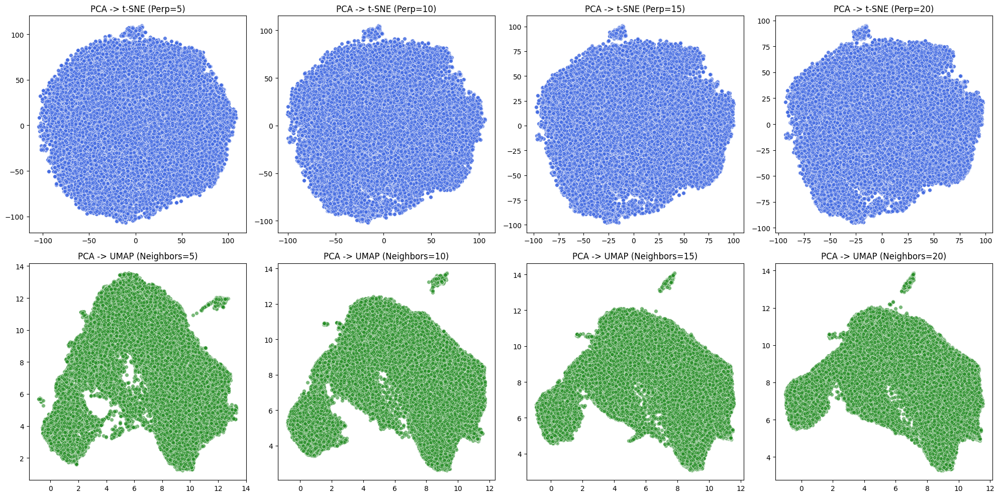

In [ ]:
# =================================================
# CELL 6: Choose Parameters for Dimensionality Reduction (t-SNE vs. UMAP)
# =================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap

# 1. LOAD DATA
# Load the DINOv2 encodings we just generated
df = pd.read_csv(os.path.join(run_dir, 'coral_dino_encodings.csv'))

# Isolate just the 384 dimensions (dim_0 to dim_383)
features = df.filter(regex='^dim_').values

# 1. DENOISE WITH PCA
# We reduce from 384 dimensions to 50 to capture the core variance
print("Denoising data with PCA...")
pca = PCA(n_components=50, random_state=42)
features_pca = pca.fit_transform(features)

# 2. DEFINE RANGES
perplexities = [5, 10, 15, 20]
neighbors = [5, 10, 15, 20]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# --- t-SNE Row (Using PCA features) ---
for i, perp in enumerate(perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, init='pca')
    res = tsne.fit_transform(features_pca)
    axes[0, i].scatter(res[:, 0], res[:, 1], alpha=0.6, s=30, c='royalblue', edgecolors='w', linewidth=0.5)
    axes[0, i].set_title(f'PCA -> t-SNE (Perp={perp})')

# --- UMAP Row (Using PCA features) ---
for i, n in enumerate(neighbors):
    reducer = umap.UMAP(n_neighbors=n, min_dist=0.1, random_state=42)
    res = reducer.fit_transform(features_pca)
    axes[1, i].scatter(res[:, 0], res[:, 1], alpha=0.6, s=30, c='forestgreen', edgecolors='w', linewidth=0.5)
    axes[1, i].set_title(f'PCA -> UMAP (Neighbors={n})')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# CELL 7: Run k-means and show some images from each cluster
# ==========================================================

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import cv2
import ast
import numpy as np
import os

# 1. LOAD DATA
# Load the DINOv2 encodings we just generated
df = pd.read_csv(os.path.join(run_dir, 'coral_dino_encodings_MASKS.csv'))

# Isolate just the 384 dimensions (dim_0 to dim_383)
features = df.filter(regex='^dim_').values

# 1. DENOISE WITH PCA
# We reduce from 384 dimensions to 100 to capture the core variance
print("Denoising data with PCA...")
n_components = 100
pca = PCA(n_components=n_components, random_state=42)
features_pca = pca.fit_transform(features)

total_variance = np.sum(pca.explained_variance_ratio_) * 100
print(f"✅ Total Variance Captured by {n_components} components: {total_variance:.2f}%")

# 1. SETUP OUTPUT PATHS
# We will save this inside the specific results folder
output_dir = os.path.join(base_path, 'results_all', 'iou60_sta55_pts32')
os.makedirs(output_dir, exist_ok=True)

png_path = os.path.join(output_dir, 'cluster_summary_MASKS.png')
pdf_path = os.path.join(output_dir, 'cluster_summary_MASKS.pdf')

# 2. ENSURE DATAFRAME IS READY
if 'final_df' in locals() and 'df' not in locals():
    df = final_df

# 3. MATHEMATICAL CLUSTERING (K-MEANS)
print("Running K-Means clustering...")
n_clusters = 50
clusterer = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df['cluster'] = clusterer.fit_predict(features_pca)

# 4. VISUALIZATION GALLERY (MULTI-PAGE)
clusters_per_page = 10
n_pages = int(np.ceil(n_clusters / clusters_per_page))

print(f"Generating visualization across {n_pages} pages...")

with PdfPages(pdf_path) as pdf:
    for p in range(n_pages):
        start_c = p * clusters_per_page
        end_c = min((p + 1) * clusters_per_page, n_clusters)
        current_n = end_c - start_c

        # Create a figure for this page only
        fig, axes = plt.subplots(current_n, 5, figsize=(15, 3 * current_n))
        fig.suptitle(f'DINOv2 Cluster Analysis (Clusters {start_c} to {end_c-1})', fontsize=20)

        for idx, c in enumerate(range(start_c, end_c)):
            cluster_samples = df[df['cluster'] == c]

            # Label the row
            count = len(cluster_samples)
            percentage = (count / len(df)) * 100
            axes[idx, 0].set_ylabel(f'Cluster {c}\n{count} items\n({percentage:.1f}%)',
                                    size='large', rotation=0, labelpad=50, fontweight='bold')

            # Get up to 5 samples
            n_samples = min(len(cluster_samples), 5)
            if n_samples > 0:
                samples = cluster_samples.sample(n_samples).to_dict('records')
                for i, sample in enumerate(samples):
                    img_path = os.path.join(data_path, sample['image_name'])
                    if os.path.exists(img_path):
                        image = cv2.imread(img_path)
                        if image is not None:
                            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                            bbox = ast.literal_eval(sample['bbox']) if isinstance(sample['bbox'], str) else sample['bbox']
                            x, y, w, h = map(int, bbox)
                            crop = image[max(0,y):y+h, max(0,x):x+w]
                            axes[idx, i].imshow(crop)

            # Style Cleanup
            for i in range(5):
                axes[idx, i].set_xticks([]); axes[idx, i].set_yticks([])
                if i >= n_samples:
                    axes[idx, i].axis('off')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        pdf.savefig(fig) # Save current page to PDF

        # If it's the first page, save a PNG preview as well
        if p == 0:
            fig.savefig(png_path, dpi=150, bbox_inches='tight')

        plt.close(fig) # Memory cleanup

print(f"✅ All {n_clusters} clusters saved successfully to: {pdf_path}")

Denoising data with PCA...
✅ Total Variance Captured by 100 components: 88.73%
Running K-Means clustering...
Generating visualization across 5 pages...
✅ All 50 clusters saved successfully to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/cluster_summary_MASKS.pdf


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


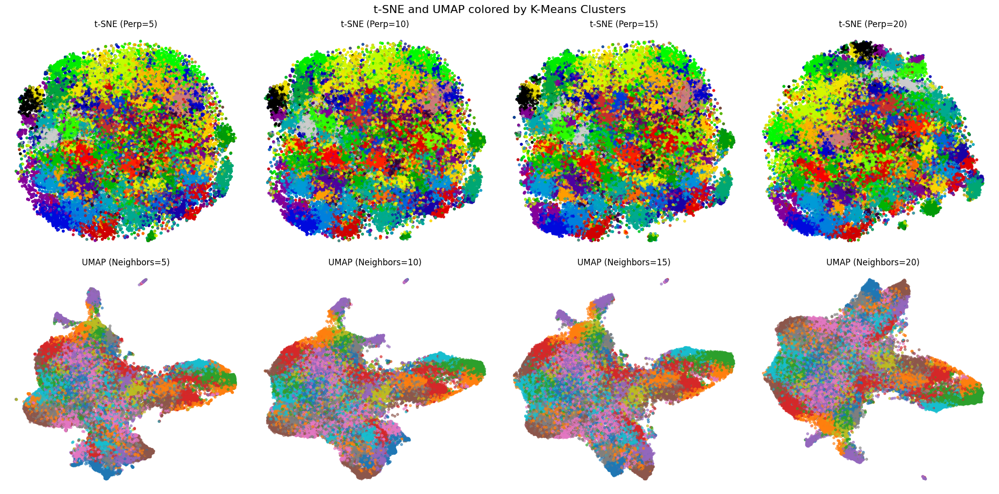

In [ ]:
# =================================================
# CELL 8 (or re-run Cell 6): Visualize Clusters on t-SNE/UMAP
# =================================================

from sklearn.manifold import TSNE
import umap

# 1. MAKE SURE CLUSTERS EXIST
if 'cluster' not in df.columns:
    raise ValueError("⚠️ Please run the K-Means Cell (Cell 7) first to generate clusters!")

# 2. DEFINE RANGES
perplexities = [5, 10, 15, 20]
neighbors = [5, 10, 15, 20]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle(f"t-SNE and UMAP colored by K-Means Clusters", fontsize=16)

# --- t-SNE Row ---
for i, perp in enumerate(perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, init='pca', learning_rate='auto')
    res = tsne.fit_transform(features_pca)

    # CHANGE IS HERE: c=df['cluster'], cmap='tab10'
    axes[0, i].scatter(res[:, 0], res[:, 1],
                       c=df['cluster'],   # <--- Color by cluster ID
                       cmap='nipy_spectral',      # <--- Use distinct colors
                       alpha=0.6, s=10)   # s=10 makes dots smaller to see boundaries better
    axes[0, i].set_title(f't-SNE (Perp={perp})')
    axes[0, i].axis('off')

# --- UMAP Row ---
for i, n in enumerate(neighbors):
    reducer = umap.UMAP(n_neighbors=n, min_dist=0.1, random_state=42)
    res = reducer.fit_transform(features_pca)

    # CHANGE IS HERE: c=df['cluster'], cmap='tab10'
    axes[1, i].scatter(res[:, 0], res[:, 1],
                       c=df['cluster'],   # <--- Color by cluster ID
                       cmap='tab10',      # <--- Use 10 distinct colors
                       alpha=0.6, s=10)
    axes[1, i].set_title(f'UMAP (Neighbors={n})')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

✅ Comparison table saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/Coral_Segmentation_Comparison.jpg


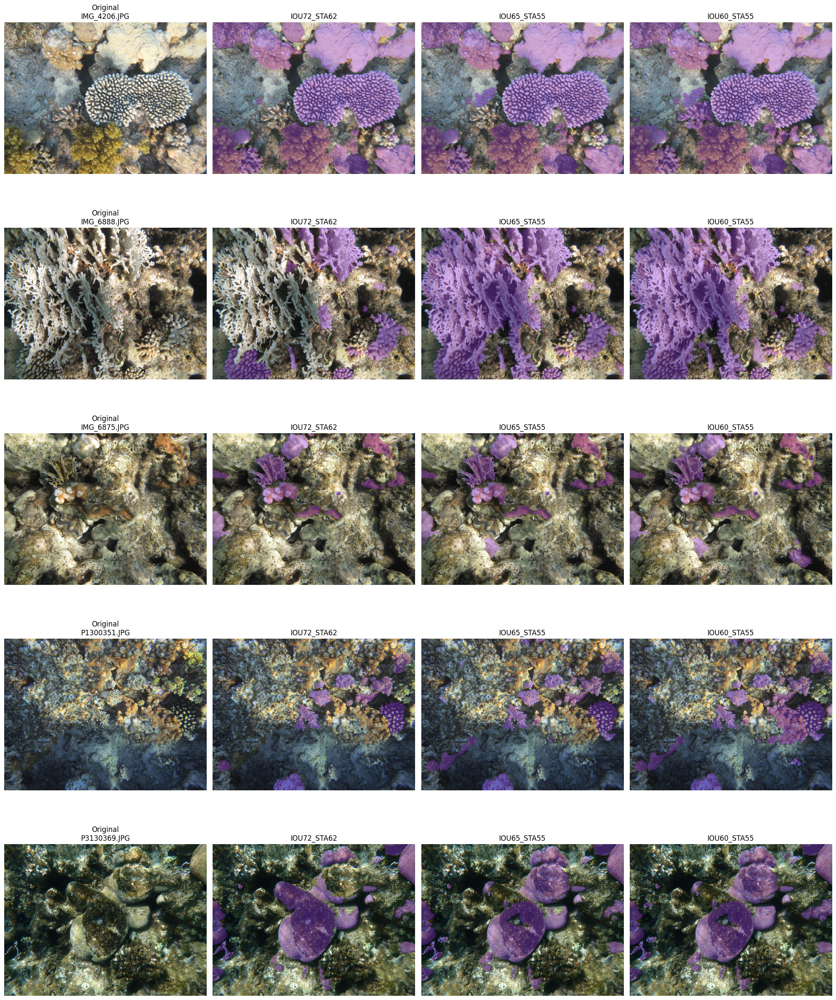

In [ ]:
# =================================================
# CELL 9 Compare parameters of segmentation for example images
# =================================================

import matplotlib.pyplot as plt
import cv2
import os

# 1. DEFINE PATHS TO YOUR SAVED RESULTS
# Update these paths to match where your segmented images are stored
results_base = os.path.join(base_path, 'results')
output_file_path = os.path.join(base_path, 'Coral_Segmentation_Comparison.jpg')

parameter_sets = [
    ("IOU72_STA62", os.path.join(results_base, "iou72_sta62_pts32/visualizations")),
    ("IOU65_STA55", os.path.join(results_base, "iou65_sta55_pts32/visualizations")),
    ("IOU60_STA55", os.path.join(results_base, "iou60_sta55_pts32/visualizations"))
]

test_images = ["IMG_4206.JPG", "IMG_6888.JPG", "IMG_6875.JPG", "P1300351.JPG", "P3130369.JPG"]

# 2. GENERATE TABLE
fig, axes = plt.subplots(len(test_images), len(parameter_sets) + 1, figsize=(20, 5 * len(test_images)))

for row, img_name in enumerate(test_images):
    # Column 0: Original Image
    orig_path = os.path.join(data_path, img_name)
    if os.path.exists(orig_path):
        img_orig = cv2.cvtColor(cv2.imread(orig_path), cv2.COLOR_BGR2RGB)
        axes[row, 0].imshow(img_orig)
        axes[row, 0].set_title(f"Original\n{img_name}")
    axes[row, 0].axis('off')

    # Columns 1-3: Saved Segmentations
    for col, (label, folder_path) in enumerate(parameter_sets, start=1):
        seg_img_path = os.path.join(folder_path, img_name)

        if os.path.exists(seg_img_path):
            img_seg = cv2.cvtColor(cv2.imread(seg_img_path), cv2.COLOR_BGR2RGB)
            axes[row, col].imshow(img_seg)
            axes[row, col].set_title(f"{label}")
        else:
            axes[row, col].text(0.5, 0.5, 'Not Found', ha='center', va='center')
            axes[row, col].set_title(f"{label} (Missing)")

        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig(output_file_path, dpi=200, bbox_inches='tight')
print(f"✅ Comparison table saved to: {output_file_path}")
plt.show()


In [ ]:
# ===========================================================
# CELL 9.5: Clean the Data-Sets
# ===========================================================

import os
import json
import cv2
import numpy as np
from tqdm import tqdm
from pycocotools import mask as maskUtils

# Thresholds
MIN_AREA            = 25000
CONTAINMENT_THRESH  = 0.80
MAX_ASPECT_RATIO    = 3.0
SHARPNESS_THRESHOLD = 80

# CLEANING FUNCTIONS
def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return maskUtils.decode(rle).astype(bool)

def bbox_intersection(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix = max(0, min(x1+w1, x2+w2) - max(x1, x2))
    iy = max(0, min(y1+h1, y2+h2) - max(y1, y2))
    return ix * iy

def aspect_ratio(bbox):
    _, _, w, h = bbox
    return max(w, h) / max(min(w, h), 1)

def filter_annotations(annotations, min_area, containment_thresh, max_aspect_ratio):
    # Removes small images based on area
    candidates = [a for a in annotations if a['area'] >= min_area]
    # Removes images with an aspect ratio greater than the threshold
    candidates = [a for a in candidates if aspect_ratio(a['bbox']) <= max_aspect_ratio]

    if len(candidates) <= 1:
        return candidates

    to_remove = set()
    for i in range(len(candidates)):
        for j in range(len(candidates)):
            if i == j or candidates[j]['id'] in to_remove:
                continue
            a_small, a_large = candidates[i], candidates[j]
            if a_large['area'] <= a_small['area']:
                continue
            if bbox_intersection(a_small['bbox'], a_large['bbox']) == 0:
                continue

            # Check for containment
            mask_small = decode_rle(a_small['segmentation'])
            mask_large = decode_rle(a_large['segmentation'])
            containment = np.logical_and(mask_small, mask_large).sum() / a_small['area']
            if containment >= containment_thresh:
                to_remove.add(a_large['id'])

    return [a for a in candidates if a['id'] not in to_remove]


def is_sharp_enough(crop, threshold=50.0):
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var() >= threshold


def get_masked_crop(img, bbox, rle, padding_pct=0.05, background="black", min_visible=500):
    mask = decode_rle(rle)
    if mask.shape != img.shape[:2]:
        mask = cv2.resize(mask.astype(np.uint8),
                          (img.shape[1], img.shape[0]),
                          interpolation=cv2.INTER_NEAREST).astype(bool)
    bg_val = {"black": 0, "gray": 128, "white": 255}.get(background, 0)
    masked_img = img.copy()
    masked_img[~mask] = bg_val
    x, y, w, h = map(int, bbox)
    pad_w = int(w * padding_pct)
    pad_h = int(h * padding_pct)
    x1 = max(0, x - pad_w)
    y1 = max(0, y - pad_h)
    x2 = min(img.shape[1], x + w + pad_w)
    y2 = min(img.shape[0], y + h + pad_h)
    crop = masked_img[y1:y2, x1:x2]
    if crop.size == 0:
        return None

    # Filters out masks that are too small
    visible = np.any(crop != bg_val, axis=2).sum()
    if visible < min_visible:
        return None

    return crop

# Create the new destination folder for your clean sub-dataset
cleaned_json_dir = os.path.join(base_path, 'cleaned_jsons_filtered')
os.makedirs(cleaned_json_dir, exist_ok=True)

json_files = [f for f in os.listdir(json_dir) if f.endswith('.json')]
print(f"Filtering {len(json_files)} files to build clean sub-dataset...")

for j_file in tqdm(json_files, desc="Cleaning Dataset"):
    path = os.path.join(json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)
    if not os.path.exists(img_path): continue

    image = cv2.imread(img_path)
    if image is None: continue
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 1. Step A: Filter out tiny boxes, stretched boxes, and overlapping containment boxes
    raw_annotations = data['annotations']
    filtered_annos = filter_annotations(raw_annotations, MIN_AREA, CONTAINMENT_THRESH, MAX_ASPECT_RATIO)

    final_clean_annotations = []

    # 2. Step B: Filter out blurry crops using the image processing functions
    for anno in filtered_annos:
        # Generate the crop to check sharpness
        crop = get_masked_crop(image, anno['bbox'], anno['segmentation'], padding_pct=0.05)
        if crop is None: continue

        # Sharpness check
        if not is_sharp_enough(crop, threshold=SHARPNESS_THRESHOLD):
            continue # Skip blurry corals!

        # If it passes all tests, keep it
        final_clean_annotations.append(anno)

    # 3. Save a new JSON file ONLY if it still contains valid corals after filtering
    if len(final_clean_annotations) > 0:
        clean_data = data.copy()
        clean_data['annotations'] = final_clean_annotations

        out_path = os.path.join(cleaned_json_dir, j_file)
        with open(out_path, 'w') as f:
            json.dump(clean_data, f, indent=2)

print(f"\n✅ Sub-dataset creation finished! Clean JSON files saved to: {cleaned_json_dir}")

Filtering 1714 files to build clean sub-dataset...


Cleaning Dataset: 100%|██████████| 1714/1714 [2:28:40<00:00,  5.20s/it]


✅ Sub-dataset creation finished! Clean JSON files saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/cleaned_jsons_filtered


In [ ]:
import os
import json
import cv2
from tqdm import tqdm

# =====================================================================
# SELF-CONTAINED HARVESTER (Targeting the 'json' folder)
# =====================================================================
RUN_NAME = "iou60_sta55_pts32"

base_path = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path = os.path.join(base_path, 'data_all')
run_dir = os.path.join(base_path, 'results_all', RUN_NAME)

# Updating the source to point directly to the verified json folder
cleaned_json_dir = os.path.join(run_dir, 'json')
clean_images_dir = os.path.join(run_dir, 'cleaned_images_crops')

# Ensure the output directory is ready
os.makedirs(clean_images_dir, exist_ok=True)

def get_quick_crop(img_path, bbox):
    if not os.path.exists(img_path): return None
    img = cv2.imread(img_path)
    if img is None: return None

    x, y, w, h = map(int, bbox)
    x, y = max(0, x), max(0, y)
    crop = img[y:y+h, x:x+w]
    return crop if crop.size > 0 else None

# Load the files
clean_json_files = sorted([f for f in os.listdir(cleaned_json_dir) if f.endswith('.json')])
print(f"Harvesting crops based on configurations in: {cleaned_json_dir}")

for j_file in tqdm(clean_json_files, desc="Harvesting Clean Images"):
    path = os.path.join(cleaned_json_dir, j_file)
    with open(path, 'r') as f:
        data = json.load(f)

    img_name = data['image']['file_name']
    img_path = os.path.join(data_path, img_name)

    if not os.path.exists(img_path): continue

    for anno in data['annotations']:
        crop_bgr = get_quick_crop(img_path, anno['bbox'])
        if crop_bgr is None: continue

        crop_filename = f"clean_crop_{anno['id']}_{img_name}"
        crop_save_path = os.path.join(clean_images_dir, crop_filename)

        cv2.imwrite(crop_save_path, crop_bgr)

print(f"\n✅ Crop collection complete! Verified crops saved to: {clean_images_dir}")

Harvesting crops based on configurations in: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/json


Harvesting Clean Images: 100%|██████████| 1714/1714 [2:14:09<00:00,  4.70s/it]


✅ Crop collection complete! Verified crops saved to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/cleaned_images_crops


In [ ]:
# ===========================================================
# CELL 10: Inter-class Separation and Compactness Calculation
# ===========================================================

import os
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import cosine_similarity

def analyze_kmeans_embeddings(embeddings, num_clusters):
    """
    Applies K-means clustering to the embeddings and evaluates the resulting clusters.
    """
    # 1. Normalize embeddings to project them onto the unit hypersphere
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
    normalized_embeddings = embeddings / (norms + 1e-8)

    # 2. Run K-means using Cosine/Normalized distance orientation
    # Standard K-means uses Euclidean distance, but running it on normalized vectors
    # effectively groups them by angular/cosine similarity (perfect for DINOv2)
    kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(normalized_embeddings)

    print(f"\n==========================================")
    print(f"       ANALYSIS FOR K = {num_clusters} CLUSTERS")
    print(f"==========================================")

    # 3. Global Clustering Metrics
    sil = silhouette_score(normalized_embeddings, cluster_labels, metric='cosine')
    db = davies_bouldin_score(normalized_embeddings, cluster_labels)
    print(f"Global Silhouette Score (Cosine): {sil:.4f}  (Closer to 1.0 is better)")
    print(f"Davies-Bouldin Index:             {db:.4f}  (Closer to 0.0 is better)\n")

    # 4. Intra-Class Compactness
    print("=== Cluster Compactness (Average similarity to cluster center) ===")
    unique_clusters = np.unique(cluster_labels)
    for cluster in unique_clusters:
        cls_mask = (cluster_labels == cluster)
        cls_embeddings = normalized_embeddings[cls_mask]

        centroid = kmeans.cluster_centers_[cluster]
        # Ensure centroid is normalized
        centroid = centroid / (np.linalg.norm(centroid) + 1e-8)

        similarities = cosine_similarity(cls_embeddings, centroid.reshape(1, -1))
        avg_compactness = np.mean(similarities)
        print(f"Cluster {cluster}: Compactness = {avg_compactness:.4f} (Count = {len(cls_embeddings)})")

    # 5. Inter-Class Separation Matrix
    print("\n=== Inter-Cluster Similarity Matrix ===")
    print("Values close to 0.0 mean distinct clusters; values close to 1.0 mean heavily overlapping clusters.")
    num_classes = len(unique_clusters)
    separation_matrix = np.zeros((num_classes, num_classes))

    for i in range(num_classes):
        for j in range(num_classes):
            if i == j:
                separation_matrix[i, j] = 1.0
            else:
                cent_i = kmeans.cluster_centers_[i]
                cent_j = kmeans.cluster_centers_[j]
                sim = cosine_similarity(cent_i.reshape(1, -1), cent_j.reshape(1, -1))[0][0]
                separation_matrix[i, j] = sim

    header = "\t" + "\t".join([f"Clus_{c}" for c in unique_clusters])
    print(header)
    for i, row in enumerate(separation_matrix):
        row_str = f"Clus_{i}\t" + "\t".join([f"{val:.3f}" for val in row])
        print(row_str)

    return cluster_labels

# --- RUNNING WITH YOUR REAL DATA ---
if __name__ == "__main__":
    # run_dir = 'your/directory/path/here' # Update this path
    df = pd.read_csv(os.path.join(run_dir, 'coral_DinoVdeau_encodings_MASKS_cleaned.csv'))
   # Filter columns to ONLY include those that start with "dim_"
    # This completely ignores indices, labels, paths, or mask areas!
    feature_cols = [col for col in df.columns if col.startswith('dim_')]

    real_embeddings = df[feature_cols].values

    print(f"Total columns found in CSV: {len(df.columns)}")
    print(f"Successfully isolated true DINO features!")
    print(f"Final Matrix Shape: {real_embeddings.shape[0]} samples x {real_embeddings.shape[1]} features")

    # Double-check: should be exactly 384 (from dim_0 to dim_383)
    if real_embeddings.shape[1] != 384:
        print(f"WARNING: Found {real_embeddings.shape[1]} dimensions instead of 384. Check if features are missing.")

    # Test different numbers of clusters to see what makes the most sense for your data
    # For example, let's test if your data naturally fits into 2, 3, or 4 distinct groups:
    for k in [2, 4, 6]:
        labels = analyze_kmeans_embeddings(real_embeddings, num_clusters=k)

    # Optional: Save the generated cluster labels back to your CSV for tracking
    # optimal_labels = analyze_kmeans_embeddings(real_embeddings, num_clusters=3)
    # df['kmeans_cluster_labels'] = optimal_labels
    # df.to_csv(os.path.join(run_dir, 'coral_dino_encodings_with_KMEANS.csv'), index=False)

Total columns found in CSV: 1027
Successfully isolated true DINO features!
Final Matrix Shape: 18630 samples x 1024 features

       ANALYSIS FOR K = 2 CLUSTERS
Global Silhouette Score (Cosine): 0.2746  (Closer to 1.0 is better)
Davies-Bouldin Index:             1.8622  (Closer to 0.0 is better)

=== Cluster Compactness (Average similarity to cluster center) ===
Cluster 0: Compactness = 0.6652 (Count = 15101)
Cluster 1: Compactness = 0.7889 (Count = 3529)

=== Inter-Cluster Similarity Matrix ===
Values close to 0.0 mean distinct clusters; values close to 1.0 mean heavily overlapping clusters.
	Clus_0	Clus_1
Clus_0	1.000	0.516
Clus_1	0.516	1.000

       ANALYSIS FOR K = 4 CLUSTERS
Global Silhouette Score (Cosine): 0.2377  (Closer to 1.0 is better)
Davies-Bouldin Index:             2.5814  (Closer to 0.0 is better)

=== Cluster Compactness (Average similarity to cluster center) ===
Cluster 0: Compactness = 0.7923 (Count = 3466)
Cluster 1: Compactness = 0.7327 (Count = 6714)
Cluster 2: Co

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import umap
import hdbscan

if __name__ == "__main__":
    TARGET_CSV = 'coral_dinoV3_encodings.csv' # or your masks file
    csv_path = os.path.join(run_dir, TARGET_CSV)
    df = pd.read_csv(csv_path)

    # 1. Isolate and Clean Features via PCA (Dropping lighting component 0)
    feature_cols = [col for col in df.columns if col.startswith('dim_')]
    real_embeddings = df[feature_cols].values

    pca = PCA(n_components=50, random_state=42)
    pca_features = pca.fit_transform(real_embeddings)
    pca_features_cleaned = pca_features.copy()
    pca_features_cleaned[:, 0] = 0
    cleaned_embeddings = pca.inverse_transform(pca_features_cleaned)
    print(f"Loaded {len(cleaned_embeddings)} samples. Noise component 0 removed.")

    # 2. Project into Low-Dimensional UMAP Space
    # We reduce to 5 dimensions so HDBSCAN can crunch densities accurately
    print("Projecting continuous manifold with UMAP (Compressing 1024 -> 5 dims)...")
    reducer = umap.UMAP(
        n_components=5,
        metric='cosine',
        n_neighbors=30,
        min_dist=0.0,
        random_state=42
    )
    umap_features = reducer.fit_transform(cleaned_embeddings)

    # 3. Apply Density-Based HDBSCAN Clustering
    print("Running HDBSCAN dense cluster extractor...")
    # min_cluster_size: Minimum number of corals needed to form a valid category
    # min_samples: Controls how conservative the clustering is (higher = more noise)
    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=500,
        min_samples=50,
        metric='euclidean',
        prediction_data=True
    )
    cluster_labels = clusterer.fit_predict(umap_features)

    # 4. Process and Analyze Results
    unique_labels = np.unique(cluster_labels)
    num_real_clusters = len([l for l in unique_labels if l != -1])

    # Filter out noise points to evaluate the quality of the actual clusters discovered
    is_not_noise = (cluster_labels != -1)
    valid_features = umap_features[is_not_noise]
    valid_labels = cluster_labels[is_not_noise]

    print(f"\n==========================================")
    print(f"        HDBSCAN EXTRACTION REPORT")
    print(f"==========================================")
    print(f"Total Natural Clusters Discovered: {num_real_clusters}")
    print(f"Total Samples Categorized: {np.sum(is_not_noise)} / {len(df)}")
    print(f"Total Noise Points Filtered Out: {np.sum(cluster_labels == -1)}")

    if num_real_clusters > 1:
        # Evaluate on the UMAP space where the density groupings exist
        sil = silhouette_score(valid_features, valid_labels)
        db = davies_bouldin_score(valid_features, valid_labels)
        print(f"\nGlobal Silhouette Score (Excluding Noise): {sil:.4f}  (Should be high!)")
        print(f"Davies-Bouldin Index (Excluding Noise):     {db:.4f}")

        print("\n=== Discovered Categories Distribution ===")
        for cluster in unique_labels:
            count = np.sum(cluster_labels == cluster)
            pct = (count / len(df)) * 100
            if cluster == -1:
                print(f"Unassigned Noise Category: Count = {count} ({pct:.1f}%)")
            else:
                print(f"Biological Cluster {cluster}: Count = {count} ({pct:.1f}%)")

        # Save labels back to a new file for downstream exploration
        df['hdbscan_cluster'] = cluster_labels
        output_csv = os.path.join(run_dir, 'coral_hdbscan_results.csv')
        df.to_csv(output_csv, index=False)
        print(f"\n📁 Saved cluster mappings to: {output_csv}")
    else:
        print("❌ HDBSCAN couldn't find distinct high-density splits with these parameters.")

Loaded 44211 samples. Noise component 0 removed.
Projecting continuous manifold with UMAP (Compressing 1024 -> 5 dims)...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running HDBSCAN dense cluster extractor...

        HDBSCAN EXTRACTION REPORT
Total Natural Clusters Discovered: 6
Total Samples Categorized: 30420 / 44211
Total Noise Points Filtered Out: 13791

Global Silhouette Score (Excluding Noise): 0.4475  (Should be high!)
Davies-Bouldin Index (Excluding Noise):     0.7202

=== Discovered Categories Distribution ===
Unassigned Noise Category: Count = 13791 (31.2%)
Biological Cluster 0: Count = 5382 (12.2%)
Biological Cluster 1: Count = 4388 (9.9%)
Biological Cluster 2: Count = 13252 (30.0%)
Biological Cluster 3: Count = 3525 (8.0%)
Biological Cluster 4: Count = 537 (1.2%)
Biological Cluster 5: Count = 3336 (7.5%)

📁 Saved cluster mappings to: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_hdbscan_results.csv


Compressing data into a 2D visual map using UMAP...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


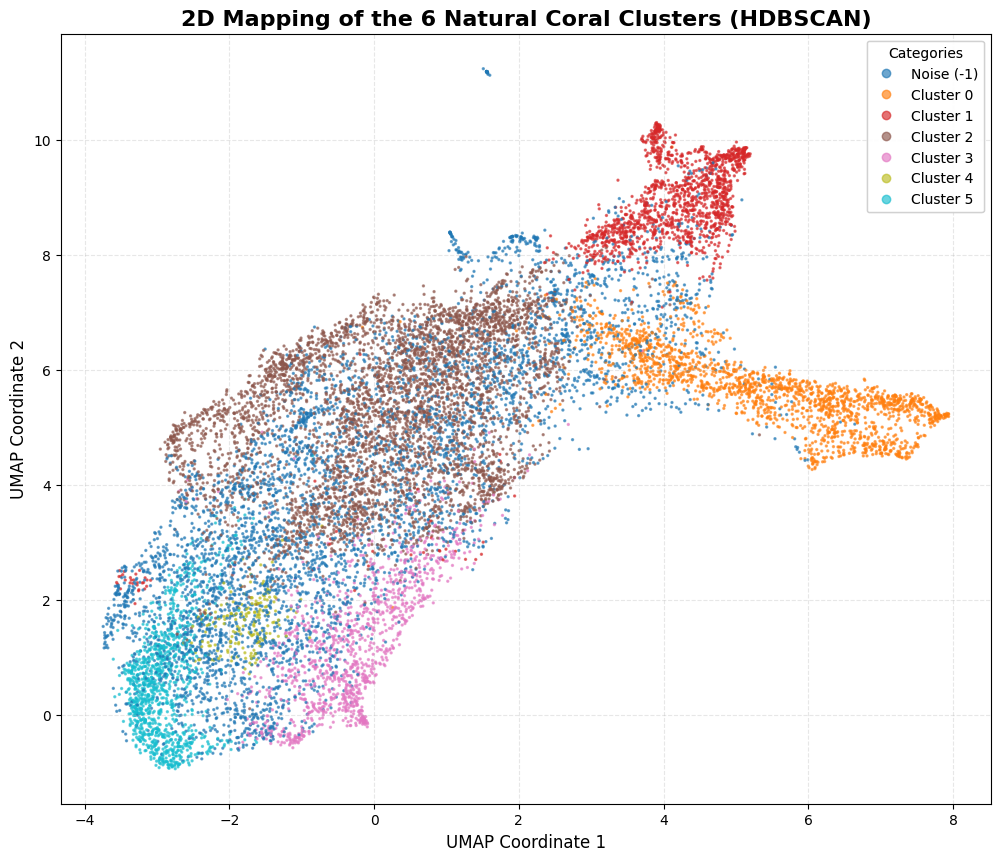

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap

# 1. Load the results file that contains the new 'hdbscan_cluster' column
# (Using the exact path printed by your previous run)
results_csv = "/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_hdbscan_results.csv"
df_results = pd.read_csv(results_csv)

# 2. Extract the features and cluster labels
feature_cols = [col for col in df_results.columns if col.startswith('dim_')]
embeddings = df_results[feature_cols].values
labels = df_results['hdbscan_cluster'].values

print("Compressing data into a 2D visual map using UMAP...")

# 3. Create a 2D projection strictly for drawing the map
# We sample 15,000 points so the plot renders instantly and doesn't look like an overcrowded blob
np.random.seed(42)
sample_indices = np.random.choice(len(embeddings), size=15000, replace=False)

embedding_sample = embeddings[sample_indices]
labels_sample = labels[sample_indices]

reducer_2d = umap.UMAP(metric='cosine', n_neighbors=30, min_dist=0.1, random_state=42)
umap_2d = reducer_2d.fit_transform(embedding_sample)

# 4. Draw the Plot
plt.figure(figsize=(12, 10))

# We use the 'tab10' or 'Set1' color palette so each cluster gets a vibrant, distinct color
# Noise (-1) will automatically map to a dark gray color so it doesn't distract from the clusters
scatter = plt.scatter(
    umap_2d[:, 0],
    umap_2d[:, 1],
    c=labels_sample,
    cmap='tab10',
    s=2,
    alpha=0.6
)

# 5. Format and present cleanly inside the notebook
plt.title("2D Mapping of the 6 Natural Coral Clusters (HDBSCAN)", fontsize=16, fontweight='bold')
plt.xlabel("UMAP Coordinate 1", fontsize=12)
plt.ylabel("UMAP Coordinate 2", fontsize=12)

# Create a clean interactive legend mapping colors back to actual cluster IDs
legend1 = plt.legend(*scatter.legend_elements(), title="Categories", loc="upper right")
plt.gca().add_artist(legend1)

# Modify legend labels manually so "-1" displays clearly as "Noise"
for text in legend1.get_texts():
    if "−1" in text.get_text() or "-1" in text.get_text():
        text.set_text("Noise (-1)")
    else:
        num = text.get_text().replace("$\\mathdefault{", "").replace("}$", "")
        text.set_text(f"Cluster {num}")

plt.grid(True, linestyle='--', alpha=0.3)
plt.show() # Forces the plot to render directly inside your notebook window

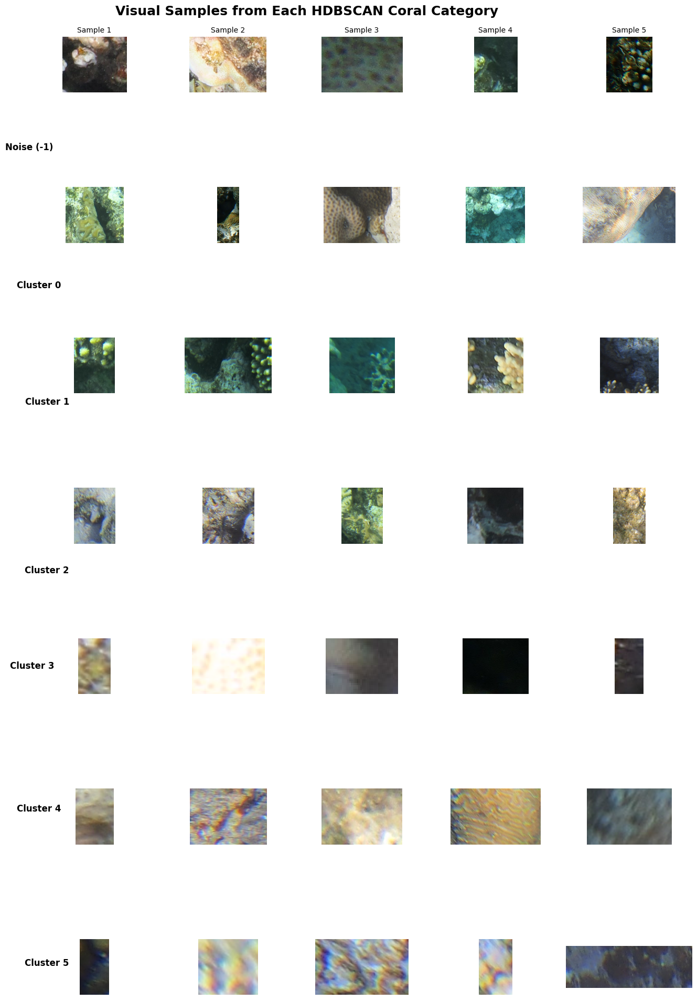

In [ ]:
import os
import cv2
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load your results data
results_csv = "/content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/coral_hdbscan_results.csv"
df_results = pd.read_csv(results_csv)

# 2. Setup the plot parameters
# 7 Categories total (Noise + 6 Clusters). We show 5 examples per category.
categories = [-1, 0, 1, 2, 3, 4, 5]
num_examples = 5

fig, axes = plt.subplots(len(categories), num_examples, figsize=(15, 20))
fig.suptitle("Visual Samples from Each HDBSCAN Coral Category", fontsize=18, fontweight='bold', y=0.95)

# Helper function to crop the image identically to how the model saw it
def get_crop_for_preview(img_path, bbox):
    if not os.path.exists(img_path): return None
    img = cv2.imread(img_path)
    if img is None: return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Simple bounding box crop
    x, y, w, h = map(int, bbox)
    # Clamp bounds to prevent crashes
    x, y = max(0, x), max(0, y)
    crop = img[y:y+h, x:x+w]
    return crop if crop.size > 0 else None

# 3. Loop through every category and gather samples
for row_idx, cat in enumerate(categories):
    # Filter rows matching this specific cluster
    cat_df = df_results[df_results['hdbscan_cluster'] == cat]

    # If a cluster has fewer than 5 images (unlikely), handle gracefully
    current_examples = min(num_examples, len(cat_df))
    if current_examples == 0:
        continue

    # Pick random samples from this category
    sampled_rows = cat_df.sample(n=current_examples, random_state=42)

    col_idx = 0
    for _, row in sampled_rows.iterrows():
        # Clean string representation of bbox back to numerical list
        bbox_str = row['bbox'].replace('[', '').replace(']', '')
        bbox = [float(val) for val in bbox_str.split()]

        # Build paths
        img_name = row['image_name']
        img_path = os.path.join(data_path, img_name) # Uses your globally defined data_path

        crop = get_crop_for_preview(img_path, bbox)

        ax = axes[row_idx, col_idx]
        if crop is not None:
            ax.imshow(crop)
        else:
            # Fallback if image path can't be reached or file is missing
            ax.text(0.5, 0.5, "Image Missing", ha='center', va='center')

        ax.axis('off') # Turn off background grid coordinates for clean display

        # Add column labels for the first row only
        if row_idx == 0:
            ax.set_title(f"Sample {col_idx+1}", fontsize=10)
        col_idx += 1

    # Fill remaining columns with blanks if cluster was too small
    for blank_col in range(col_idx, num_examples):
        axes[row_idx, blank_col].axis('off')

    # Label the entire row category on the left-most axis
    row_title = "Noise (-1)" if cat == -1 else f"Cluster {cat}"
    axes[row_idx, 0].text(-20, crop.shape[0]//2 if crop is not None else 50,
                          row_title, va='center', ha='right', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.subplots_adjust(left=0.15, top=0.92)
plt.show()